# 06 · 探索性数据分析与风险信号检验

本阶段使用 Notebook 5 清洗后的 Train 数据，开展代表性特征的探索性数据分析（EDA）。

这一阶段不追求一次扫描全部特征，也不进行自动特征删除。重点是先用一组具有代表性的数值和类别变量，建立清晰的 EDA 主线：

1. 检查 target 的整体分布和时间变化；
2. 查看 numerical feature 自身的分布、缺失和离群情况；
3. 查看 categorical feature 的类别结构；
4. 分析 feature 与 target 的基本关系；
5. 使用分箱坏账率观察 numerical feature 的风险变化；
6. 比较缺失与非缺失样本的坏账率；
7. 查看 numerical features 之间的相关关系；
8. 保存统计结果、可视化和分析结论。

本轮只读取 Train，不使用 Validation 或 OOT，也不会因为单个 EDA 指标较高或较低就直接删除特征。

**范围限制：** 暂不执行 WOE、IV、MI、Cramér's V、单变量树或完整特征池的时间稳定性检验；上述方法留待后续特征分析阶段。

## 数据流

```text
Notebook 5 的 train_clean.parquet
        ↓
选择一组代表性 numerical / categorical features
        ↓
Target 分布与按周变化
        ↓
Numerical / Categorical 单变量 EDA
        ↓
Feature 与 Target
        ↓
Numerical 分箱坏账率
        ↓
Missing vs Non-missing 坏账率
        ↓
Feature 与 Feature correlation
        ↓
保存结果与分析结论
```


> 图表标题和坐标轴统一使用英文，避免 Kaggle 默认字体缺少中文字形导致 `Glyph missing` 警告。

## 1. 数据起点：代表性特征与业务含义

Notebook 5 已经完成时间切分和基础清洗，因此本 Notebook 直接读取清洗后的 Train 数据进行 EDA。

原始宽表包含大量来自不同业务表和聚合过程的特征。第一轮 EDA 的目标不是立即筛选“最重要的特征”，而是先选择一组业务含义较清楚、能够覆盖不同风险维度的代表性变量，把完整的 EDA 过程走通。

本轮代表性特征主要覆盖：

- 贷款规模与还款负担，例如贷款金额、分期金额和首付款；
- 偿债能力与当前负债，例如收入、当前债务和活跃信用数量；
- 历史还款行为，例如分期数量和历史延迟还款比例；
- 历史申请与外部征信信息，例如 previous application 和 Credit Bureau 聚合记录；
- 客户基本画像，例如教育、收入来源、家庭状态和交易类型。

这些变量主要依据 **业务可解释性、风险维度覆盖和数据来源代表性** 进行选择，而不是根据 Pearson correlation、模型 importance 或其他 target-based 指标提前筛选。因此，它们只是本轮 EDA 的代表性样本，并不意味着已经被证明是最重要的特征。

为了方便理解每个变量，下面的特征表同时保留：

- `feature`：Notebook 5 清洗后实际使用的字段名；
- `type`：numerical 或 categorical；
- `description`：原始字段优先使用 Home Credit 官方英文定义；前面聚合过程中产生的新特征使用项目自己的说明；
- `description_source`：区分 `Official` 与 `Project-derived`；
- `selection_reason`：用中文说明为什么将该变量放入第一轮 EDA。

部分字段在前面的表内聚合过程中已经发生语义变化，因此字段名也会相应改变。例如，`gender_992L` 在 `person_1` 中属于多人记录，聚合到申请级后保留主申请人的值，因此变为 `person_main_gender_992L`。这类字段在查询官方定义时仍对应原始字段，但在建模数据中保留聚合后的名称。

此外，`WEEK_NUM`、`date_decision` 和 `MONTH` 等绝对时间字段继续保留，用于时间切分、趋势观察和后续稳定性分析，但暂时不作为模型候选特征。这样可以减少模型直接利用时间趋势作为预测捷径的风险。历史事件日期则在前面的清洗过程中尽量转换为相对申请日的时间距离，使其更接近客户自身的行为信息。

如果候选字段在 Notebook 5 清洗后不存在，当前代码会自动跳过，不影响后续 EDA。

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq
from IPython.display import display, Markdown


# ============================================================
# 读取 Notebook 5 的清洗结果
# ============================================================

TARGET_COL = "target"
WEEK_COL = "WEEK_NUM"
NUMERIC_BIN_COUNT = 5

REPORT_ROOT = Path("/kaggle/working/reports/feature_eda")
REPORT_ROOT.mkdir(parents=True, exist_ok=True)

train_matches = list(
    Path("/kaggle/input").rglob("train_clean.parquet")
)

assert len(train_matches) == 1, (
    f"应该找到 1 个 train_clean.parquet，"
    f"实际找到 {len(train_matches)} 个：{train_matches}"
)

TRAIN_PATH = train_matches[0]

# 这里只读取列名，先不把整个宽表放进内存
train_columns = pq.ParquetFile(
    TRAIN_PATH
).schema_arrow.names

print("Train path:", TRAIN_PATH)



# ============================================================
# 1. 选择本轮 EDA 要分析的代表性特征
# ============================================================

PREFERRED_NUMERICAL_FEATURES = [
    "credamount_770A",
    "annuity_780A",
    "currdebt_22A",
    "maininc_215A",
    "price_1097A",
    "downpmt_116A",
    "numactivecreds_622L",
    "numinstls_657L",
    "pctinstlsallpaidlate1d_3546856L",
    "applprev_n_records",
    "applprev_2_total_records",
    "cba1_total_records",
    "cba2_total_payments",
    "cbb1_total_records",
    "cbb2_total_payments",
    "person2_person_count",
    "debitcard_record_count",
    "deposit_record_count",
]


PREFERRED_CATEGORICAL_FEATURES = [
    "education_1103M",
    "maritalst_385M",
    "inittransactioncode_186L",
    "person_main_incometype_1044T",
    "person_main_familystate_447L",
    "person_main_gender_992L",
]


# 只保留 Notebook 5 清洗后仍然存在的字段
numeric_features = [
    feature
    for feature in PREFERRED_NUMERICAL_FEATURES
    if feature in train_columns
]

categorical_features = [
    feature
    for feature in PREFERRED_CATEGORICAL_FEATURES
    if feature in train_columns
]


# 检查有没有想分析、但当前数据里不存在的字段
requested_features = (
    PREFERRED_NUMERICAL_FEATURES
    + PREFERRED_CATEGORICAL_FEATURES
)

missing_requested_features = [
    feature
    for feature in requested_features
    if feature not in train_columns
]

print("实际使用的 numerical features 数量：", len(numeric_features))
print("实际使用的 categorical features 数量：", len(categorical_features))

if missing_requested_features:
    print("\n以下字段当前不存在，已经自动跳过：")
    for feature in missing_requested_features:
        print(" -", feature)


# 只读取本轮 EDA 真正需要的字段
eda_columns = [
    TARGET_COL,
    WEEK_COL,
    *numeric_features,
    *categorical_features,
]

train = pd.read_parquet(
    TRAIN_PATH,
    columns=eda_columns,
    engine="pyarrow",
)

eda_sample = train

print("\nTrain shape:", train.shape)


# ============================================================
# 2. 读取 Home Credit 官方字段定义
# ============================================================

# 先尝试几个常见的 Kaggle 路径
definition_candidates = [
    Path(
        "/kaggle/input/competitions/"
        "home-credit-credit-risk-model-stability/"
        "feature_definitions.csv"
    ),
    Path(
        "/kaggle/input/"
        "home-credit-credit-risk-model-stability/"
        "feature_definitions.csv"
    ),
]

definition_path = None


# 先检查常见路径
for path in definition_candidates:
    if path.exists():
        definition_path = path
        break


# 如果常见路径都没有，就在 /kaggle/input 下自动搜索
if definition_path is None:
    found_paths = list(
        Path("/kaggle/input").rglob("feature_definitions.csv")
    )

    if found_paths:
        definition_path = found_paths[0]


# 保存“字段名 -> 官方描述”的映射
official_description_map = {}


if definition_path is not None:

    feature_definitions = pd.read_csv(definition_path)

    # 自动寻找 Variable 和 Description 两列
    column_lookup = {
        column.lower(): column
        for column in feature_definitions.columns
    }

    variable_col = column_lookup.get("variable")
    description_col = column_lookup.get("description")

    if variable_col is not None and description_col is not None:

        official_description_map = (
            feature_definitions[
                [variable_col, description_col]
            ]
            .dropna(subset=[variable_col])
            .drop_duplicates(subset=[variable_col])
            .set_index(variable_col)[description_col]
            .to_dict()
        )

        print("\n已成功读取官方 feature definitions：")
        print(definition_path)

    else:
        print(
            "\n找到了 feature_definitions.csv，"
            "但没有找到 Variable / Description 两列。"
        )

else:
    print(
        "\n没有找到官方 feature_definitions.csv。"
    )


# ============================================================
# 3. 为项目自己生成的特征补充说明
# ============================================================

# 这些字段是前面聚合过程中自己生成的，
# 因此 Home Credit 官方文件里不会存在完全相同的字段名。
#
# 只有真的需要研究这些字段时，才需要在这里补充说明。
# 不需要为所有生成字段都手写 description。

PROJECT_DERIVED_DESCRIPTIONS = {

    "applprev_n_records":
        "与当前申请关联的 previous application 记录数量。",

    "applprev_2_total_records":
        "聚合后的 previous application level-2 记录数量。",

    "cba1_total_records":
        "与当前申请关联的 Credit Bureau A level-1 记录数量。",

    "cba2_total_payments":
        "Credit Bureau A level-2 中聚合后的 payment 记录数量。",

    "cbb1_total_records":
        "与当前申请关联的 Credit Bureau B level-1 记录数量。",

    "cbb2_total_payments":
        "Credit Bureau B level-2 中聚合后的 payment 记录数量。",

    "person2_person_count":
        "person_2 表中与当前申请关联的人数。",

    "debitcard_record_count":
        "与当前申请关联的 debit card 记录数量。",

    "deposit_record_count":
        "与当前申请关联的 deposit account 记录数量。",
}


# ============================================================
# 4. 为每个 EDA 特征匹配 description
# ============================================================

# 有些字段虽然来自官方原始字段，
# 但在前面的聚合过程中被加上了前缀。
#
# 例如：
# person_main_gender_992L
#        ↓
# gender_992L
#
# 所以这里会尝试去掉这些前缀，
# 再回到官方 feature_definitions.csv 查询原始字段定义。

TRANSFORMED_PREFIX_PATTERNS = [
    r"^person_main_",
    r"^person_related\d+_",
    r"^person2_person\d+_",
]


def get_feature_description(feature):

    # 情况 1：
    # 当前字段名本身就是官方原始字段名
    if feature in official_description_map:
        return (
            official_description_map[feature],
            "Official"
        )

    # 情况 2：
    # 字段在聚合过程中被改名，
    # 尝试去掉前缀后查询原始字段定义
    for pattern in TRANSFORMED_PREFIX_PATTERNS:

        original_feature = re.sub(
            pattern,
            "",
            feature
        )

        if (
            original_feature != feature
            and original_feature in official_description_map
        ):
            return (
                official_description_map[original_feature],
                "Official + transformed"
            )

    # 情况 3：
    # 这是项目自己聚合生成的新特征
    if feature in PROJECT_DERIVED_DESCRIPTIONS:
        return (
            PROJECT_DERIVED_DESCRIPTIONS[feature],
            "Project-derived"
        )

    # 情况 4：
    # 目前还没有找到对应说明
    # 不自动猜测含义，避免产生错误解释
    return (
        "暂未记录该字段说明。",
        "Unmapped"
    )


# ============================================================
# 5. 生成 EDA 特征说明表
# ============================================================

feature_rows = []


# numerical features
for feature in numeric_features:

    description, description_source = (
        get_feature_description(feature)
    )

    feature_rows.append({
        "feature": feature,
        "type": "numerical",
        "description": description,
        "description_source": description_source,
    })


# categorical features
for feature in categorical_features:

    description, description_source = (
        get_feature_description(feature)
    )

    feature_rows.append({
        "feature": feature,
        "type": "categorical",
        "description": description,
        "description_source": description_source,
    })


eda_feature_table = pd.DataFrame(feature_rows)

display(eda_feature_table)

Train path: /kaggle/input/notebooks/jing78y38/5-pandas-zjing/clean_split/train_clean.parquet
实际使用的 numerical features 数量： 18
实际使用的 categorical features 数量： 6

Train shape: (1282082, 26)

已成功读取官方 feature definitions：
/kaggle/input/competitions/home-credit-credit-risk-model-stability/feature_definitions.csv


,feature,type,description,description_source
0,credamount_770A,numerical,Loan amount or credit card limit.,Official
1,annuity_780A,numerical,Monthly annuity amount.,Official
2,currdebt_22A,numerical,Current debt amount of the client.,Official
3,maininc_215A,numerical,Client's primary income amount.,Official
4,price_1097A,numerical,Credit price.,Official
5,downpmt_116A,numerical,Amount of downpayment.,Official
6,numactivecreds_622L,numerical,Number of active credits.,Official
7,numinstls_657L,numerical,Number of instalments.,Official
8,pctinstlsallpaidlate1d_3546856L,numerical,Percentage of installments that are paid 1 or ...,Official
9,applprev_n_records,numerical,与当前申请关联的 previous application 记录数量。,Project-derived


## 2. 风险全貌：Target 分布与时间变化

后续所有“风险关系”分析都围绕 `target` 展开，因此先确认标签本身的基本结构。

这里主要查看：

- `target=0` 和 `target=1` 的样本数量；
- 两类样本各自的比例；
- Train 中每一周的样本量和坏账率。

如果 `target=1` 的比例明显较低，说明这是一个类别不平衡问题。后续模型评价不能只依赖 accuracy。

按周坏账率用于观察不同时间段的风险水平是否存在明显变化。坏账率的高低需要和当周样本量一起看，避免把小样本周的随机波动误认为稳定趋势。


,sample_count,proportion
target,,
0,1239558,0.966832
1,42524,0.033168


,WEEK_NUM,sample_count,bad_count,bad_rate
0,0,16735,400,0.023902
1,1,18841,472,0.025052
2,2,17476,465,0.026608
3,3,16108,419,0.026012
4,4,14309,404,0.028234


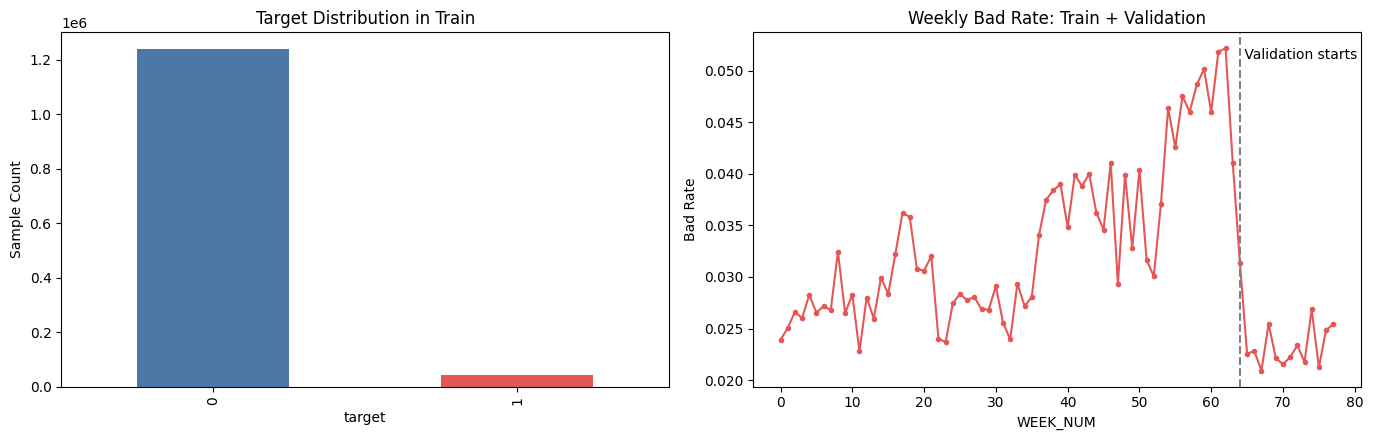

In [2]:
# =========================================================
# Target distribution：仍然只看 Train
# =========================================================

target_counts = (
    train[TARGET_COL]
    .value_counts()
    .sort_index()
)

target_proportion = (
    train[TARGET_COL]
    .value_counts(normalize=True)
    .sort_index()
)

target_table = pd.DataFrame({
    "sample_count": target_counts,
    "proportion": target_proportion,
})

display(target_table)


# =========================================================
# 时间趋势：扩大到 Train + Validation
# =========================================================

validation_matches = list(
    Path("/kaggle/input").rglob("validation_clean.parquet")
)

assert len(validation_matches) == 1, (
    f"应该找到 1 个 validation_clean.parquet，"
    f"实际找到 {len(validation_matches)} 个：{validation_matches}"
)

VALIDATION_PATH = validation_matches[0]


validation_time = pd.read_parquet(
    VALIDATION_PATH,
    columns=[WEEK_COL, TARGET_COL],
    engine="pyarrow",
)


train_time = train[
    [WEEK_COL, TARGET_COL]
].copy()


time_eda = pd.concat(
    [
        train_time,
        validation_time,
    ],
    ignore_index=True,
)


weekly_target = (
    time_eda
    .groupby(WEEK_COL)[TARGET_COL]
    .agg(
        sample_count="size",
        bad_count="sum",
        bad_rate="mean",
    )
    .reset_index()
)

display(weekly_target[:5])


# =========================================================
# Plot
# =========================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 4.5),
)


# 左图：Train target distribution
target_counts.plot.bar(
    ax=axes[0],
    color=["#4c78a8", "#e45756"],
)

axes[0].set_title(
    "Target Distribution in Train"
)

axes[0].set_xlabel(
    "target"
)

axes[0].set_ylabel(
    "Sample Count"
)


# 右图：Train + Validation 的 weekly bad rate
axes[1].plot(
    weekly_target[WEEK_COL],
    weekly_target["bad_rate"],
    marker="o",
    markersize=3,
    color="#e45756",
)

axes[1].set_title(
    "Weekly Bad Rate: Train + Validation"
)

axes[1].set_xlabel(
    "WEEK_NUM"
)

axes[1].set_ylabel(
    "Bad Rate"
)


# Week 64 是 Validation 起点
axes[1].axvline(
    x=64,
    linestyle="--",
    color="gray",
)

axes[1].text(
    64,
    weekly_target["bad_rate"].max(),
    " Validation starts",
    va="top",
)


plt.tight_layout()
plt.show()

### 时间趋势观察范围

本 Notebook 的按周坏账率统计**仅使用 Train（Week 0–63）**。图中波动可以提示训练期风险水平并非完全恒定，但不能据此断言 Week 64 发生结构性断点，更不能单凭标签比例变化判断为 concept drift。

Week 64–77 的时间外模型表现将在 Notebook 7 中另行评估；区分标签分布变化、特征分布变化和特征与目标关系变化仍需要进一步证据。


## 3. 数值画像：分布、缺失与异常

这一部分先不看 target，只描述 numerical feature 自身的分布。

统计表保留：

- `count`：非缺失样本数；
- `missing_rate`：缺失比例；
- `mean` 和 `median`：变量的典型水平；
- `std`：离散程度；
- `skewness`：分布是否明显偏斜；
- `Q1 / Q3 / IQR`：中间 50% 数据的范围；
- `IQR outlier rate`：按箱线图规则识别出的潜在离群值比例；
- `min / max`：原始范围。

IQR 离群规则为：

```text
lower bound = Q1 - 1.5 × IQR
upper bound = Q3 + 1.5 × IQR
```

被标记为离群值并不代表数据错误。信用风险数据中的极端金额、极端负债或特殊客户可能本身具有业务含义，因此这里只做识别，不自动删除。

图形部分只展示少量代表性变量。Histogram 用于观察整体形状，Boxplot 用于观察中位数、四分位区间和极端值。图形显示范围截到 P01–P99，仅用于提高可读性，不修改原始数据。


,feature,count,missing_rate,mean,median,std,skewness,q1,q3,iqr,iqr_outlier_rate,min,max
0,credamount_770A,1282082.0,0.000000,48996.697000,34291.70000,43509.510730,2.216326,19857.85,61993.40200,42135.55200,0.064194,2000.0,600000.00
1,annuity_780A,1282082.0,0.000000,3928.979205,3046.00000,2964.449449,2.571901,1913.60,5066.40000,3152.80000,0.046991,83.0,106007.00
2,currdebt_22A,1282080.0,0.000002,19072.519269,0.00000,49511.344974,4.588241,0.00,13060.66950,13060.66950,0.159004,0.0,1210629.10
3,maininc_215A,849330.0,0.337538,49192.994803,40000.00000,32182.707950,1.783051,30000.00,60000.00000,30000.00000,0.050243,0.0,200000.00
4,price_1097A,1107560.0,0.136124,34176.746277,24880.00000,34481.748061,2.652776,13540.00,44798.00000,31258.00000,0.057750,0.0,761867.44
5,downpmt_116A,1282082.0,0.000000,549.842003,0.00000,4101.897677,20.091575,0.00,0.00000,0.00000,0.060927,0.0,461867.40
6,numactivecreds_622L,1282082.0,0.000000,0.450443,0.00000,0.680803,1.444259,0.00,1.00000,1.00000,0.009055,0.0,7.00
7,numinstls_657L,1282080.0,0.000002,7.449645,0.00000,14.964016,3.524604,0.00,12.00000,12.00000,0.074388,0.0,442.00
8,pctinstlsallpaidlate1d_3546856L,880058.0,0.313571,0.178251,0.08333,0.229918,1.563725,0.00,0.27778,0.27778,0.045786,0.0,1.00
9,applprev_n_records,1012020.0,0.210643,5.134055,4.00000,4.506746,1.545938,2.00,7.00000,5.00000,0.056764,1.0,20.00


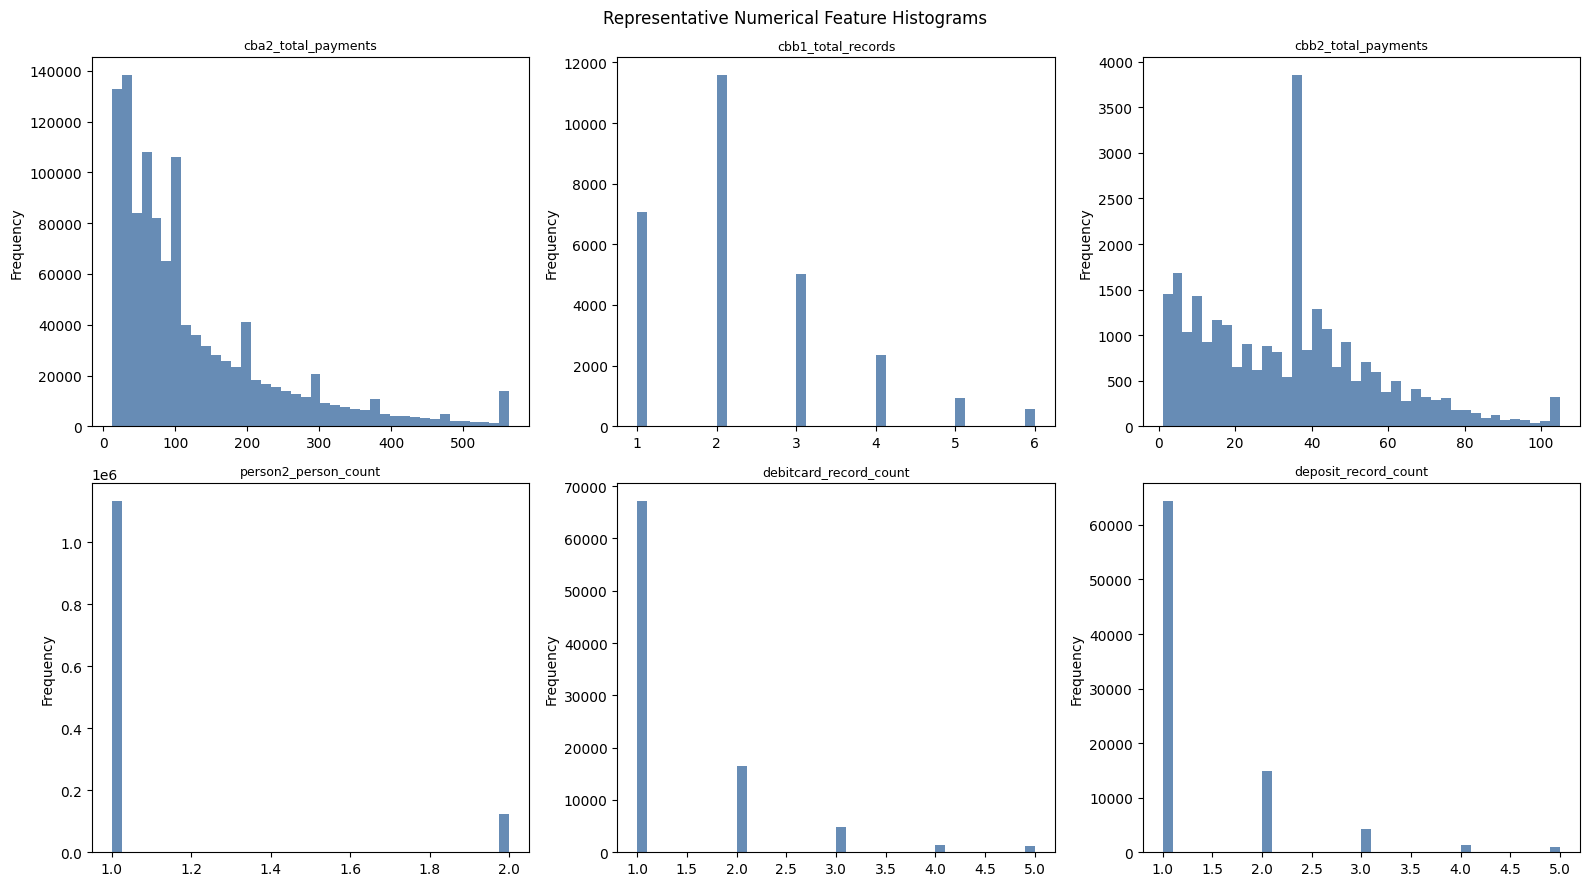

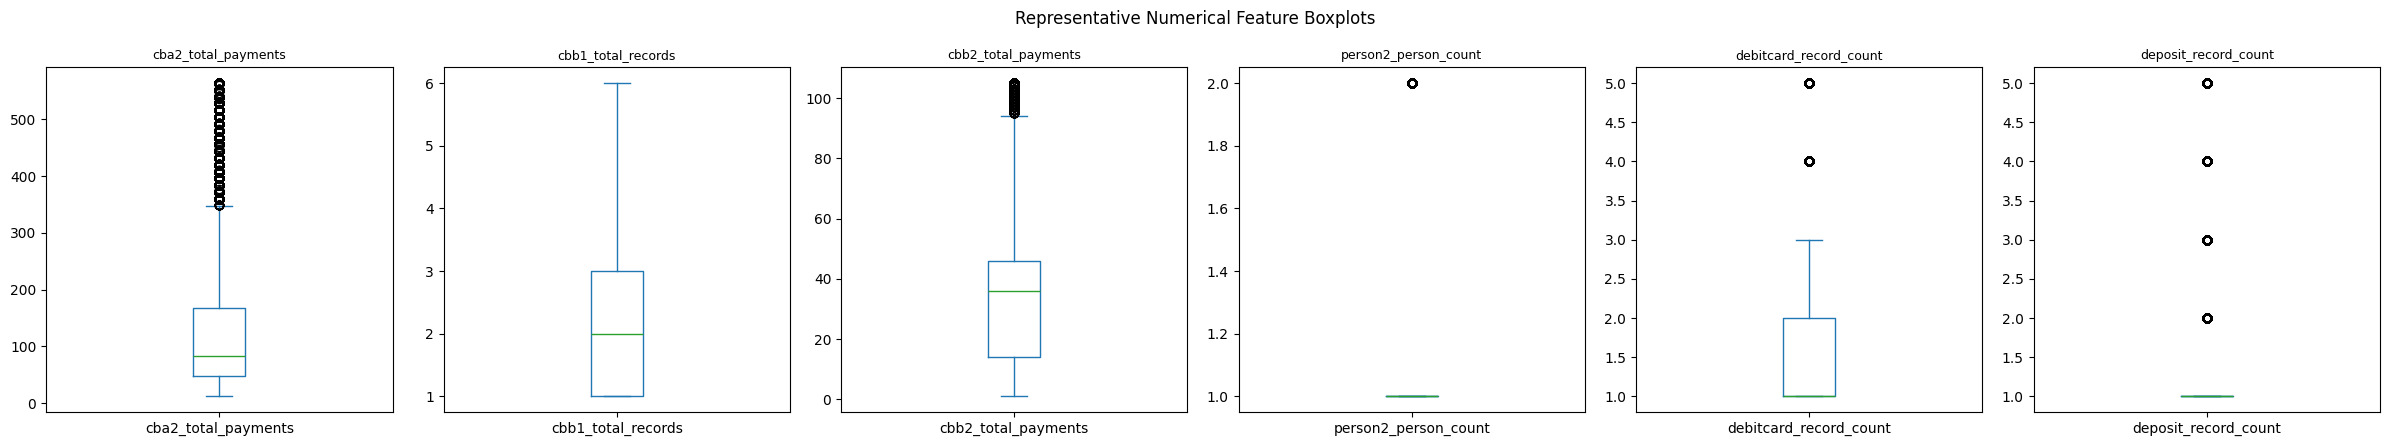

In [3]:
numeric_data = (
    eda_sample[numeric_features]
    .replace([np.inf, -np.inf], np.nan)
)

numeric_summary = numeric_data.describe().T

numeric_summary["missing_rate"] = numeric_data.isna().mean()
numeric_summary["median"] = numeric_data.median()
numeric_summary["skewness"] = numeric_data.skew()

numeric_summary = numeric_summary.rename(
    columns={
        "25%": "q1",
        "75%": "q3",
    }
)

numeric_summary["iqr"] = (
    numeric_summary["q3"]
    - numeric_summary["q1"]
)

outlier_rates = {}

for feature in numeric_features:
    q1 = numeric_summary.loc[feature, "q1"]
    q3 = numeric_summary.loc[feature, "q3"]
    iqr = numeric_summary.loc[feature, "iqr"]

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    values = numeric_data[feature].dropna()

    if len(values):
        outlier_rates[feature] = (
            (values < lower_bound)
            | (values > upper_bound)
        ).mean()
    else:
        outlier_rates[feature] = np.nan

numeric_summary["iqr_outlier_rate"] = pd.Series(
    outlier_rates
)

numeric_summary = (
    numeric_summary[
        [
            "count",
            "missing_rate",
            "mean",
            "median",
            "std",
            "skewness",
            "q1",
            "q3",
            "iqr",
            "iqr_outlier_rate",
            "min",
            "max",
        ]
    ]
    .rename_axis("feature")
    .reset_index()
)

display(numeric_summary)

histogram_features = numeric_features[12:18]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()

for axis, feature in zip(axes, histogram_features):
    values = numeric_data[feature].dropna()

    if len(values):
        lower, upper = values.quantile([0.01, 0.99])

        values.clip(lower, upper).plot.hist(
            bins=40,
            ax=axis,
            color="#4c78a8",
            alpha=0.85,
        )

    axis.set_title(feature, fontsize=9)

for axis in axes[len(histogram_features):]:
    axis.axis("off")

fig.suptitle("Representative Numerical Feature Histograms")
plt.tight_layout()
plt.show()


boxplot_features = numeric_features[12:18]

fig, axes = plt.subplots(
    1,
    len(boxplot_features),
    figsize=(4 * len(boxplot_features), 4.5),
)

axes = np.atleast_1d(axes)

for axis, feature in zip(axes, boxplot_features):
    values = numeric_data[feature].dropna()

    if len(values):
        lower, upper = values.quantile([0.01, 0.99])

        values.clip(lower, upper).plot.box(
            ax=axis
        )

    axis.set_title(feature, fontsize=9)

fig.suptitle("Representative Numerical Feature Boxplots")
plt.tight_layout()
plt.show()


### 小结：数值特征呈现出明显的长尾、零值和离散计数结构

对代表性 numerical features 的统计量、Histogram 和 Boxplot 进行检查后，可以看到不同类型的数值变量具有明显不同的分布结构。

- **金额类变量普遍呈右偏和长尾分布。**  
  `credamount_770A`、`annuity_780A`、`maininc_215A`、`price_1097A` 等变量的大部分样本集中在较低或中等区间，但仍存在少量较大的取值。Boxplot 因此会标记出较多高值离群点，但这些值可能是正常的大额贷款、高收入或高还款金额，并不能直接视为异常数据。

- **部分金额变量存在大量真实的 0。**  
  `currdebt_22A` 和 `downpmt_116A` 的分布中，大量样本集中在 0 附近，分别可能对应无当前债务或零首付等业务状态。这里的 0 与缺失值含义不同，因此不应直接作为缺失处理。

- **部分 numerical features 实际属于离散计数变量。**  
  `numactivecreds_622L`、`numinstls_657L`、`person2_person_count`、`debitcard_record_count`、`deposit_record_count` 等变量只能取 0、1、2、3 等整数值。它们虽然属于 numerical feature，但分布更接近计数数据，因此 Histogram 或频数分布通常比 Boxplot 更容易解释。

- **比例变量具有固定取值范围。**  
  `pctinstlsallpaidlate1d_3546856L` 表示历史分期延迟支付比例，取值主要位于 0–1 之间，与金额和计数变量具有不同的尺度和解释方式。

整体来看，这批 numerical features 并不服从统一的对称分布，而是同时包含长尾金额、零值集中、离散计数和比例变量等不同结构。因此，本阶段主要识别这些分布特点，不根据单纯的离群点或偏态自动删除特征；后续还需要结合它们与 `target` 的关系，判断这些分布差异是否具有实际的风险信息。

## 4. 类别画像：结构与集中度

类别变量的重点不是均值，而是类别结构。

这一部分查看：

- 非缺失样本数；
- 缺失率；
- 类别数量；
- 出现次数最多的类别；
- 最大类别所占比例；
- 每个字段最常见的若干类别。

如果某个类别占比非常高，说明分布比较集中；如果类别数量很多，则需要进一步判断它是否接近 ID、编码字段或高基数类别。

本轮只做记录，不根据类别数量直接删除特征。


,feature,count,missing_rate,category_count,top,top_count,top_proportion
0,education_1103M,1256205,2.018358e-02,5,a55475b1,733563,0.572165
1,maritalst_385M,1256205,2.018358e-02,6,a55475b1,575090,0.448559
2,inittransactioncode_186L,1282081,7.799813e-07,3,POS,966514,0.753863
3,person_main_incometype_1044T,1282082,0.000000e+00,9,PRIVATE_SECTOR_EMPLOYEE,444777,0.346918
4,person_main_familystate_447L,617570,5.183069e-01,5,MARRIED,444887,0.347004
5,person_main_gender_992L,10596,9.917353e-01,2,F,8978,0.007003


#### `education_1103M`

,sample_count,proportion
education_1103M,,
a55475b1,733563,0.572165
6b2ae0fa,371568,0.289816
717ddd49,109344,0.085286
39a0853f,37487,0.029239
<缺失>,25877,0.020184
c8e1a1d0,4243,0.003309


#### `maritalst_385M`

,sample_count,proportion
maritalst_385M,,
a55475b1,575090,0.448559
3439d993,444931,0.347038
a7fcb6e5,167342,0.130524
b6cabe76,42843,0.033417
<缺失>,25877,0.020184
38c061ee,22193,0.01731
ecd83604,3806,0.002969


...

#### `person_main_familystate_447L`

,sample_count,proportion
person_main_familystate_447L,,
<缺失>,664512,0.518307
MARRIED,444887,0.347004
SINGLE,118190,0.092186
WIDOWED,29578,0.02307
DIVORCED,17588,0.013718
LIVING_WITH_PARTNER,7327,0.005715


#### `person_main_gender_992L`

,sample_count,proportion
person_main_gender_992L,,
<缺失>,1271486,0.991735
F,8978,0.007003
M,1618,0.001262


/tmp/ipykernel_58/4095191909.py:99: UserWarning: Glyph 32570 (\N{CJK UNIFIED IDEOGRAPH-7F3A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_58/4095191909.py:99: UserWarning: Glyph 22833 (\N{CJK UNIFIED IDEOGRAPH-5931}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 32570 (\N{CJK UNIFIED IDEOGRAPH-7F3A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 22833 (\N{CJK UNIFIED IDEOGRAPH-5931}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


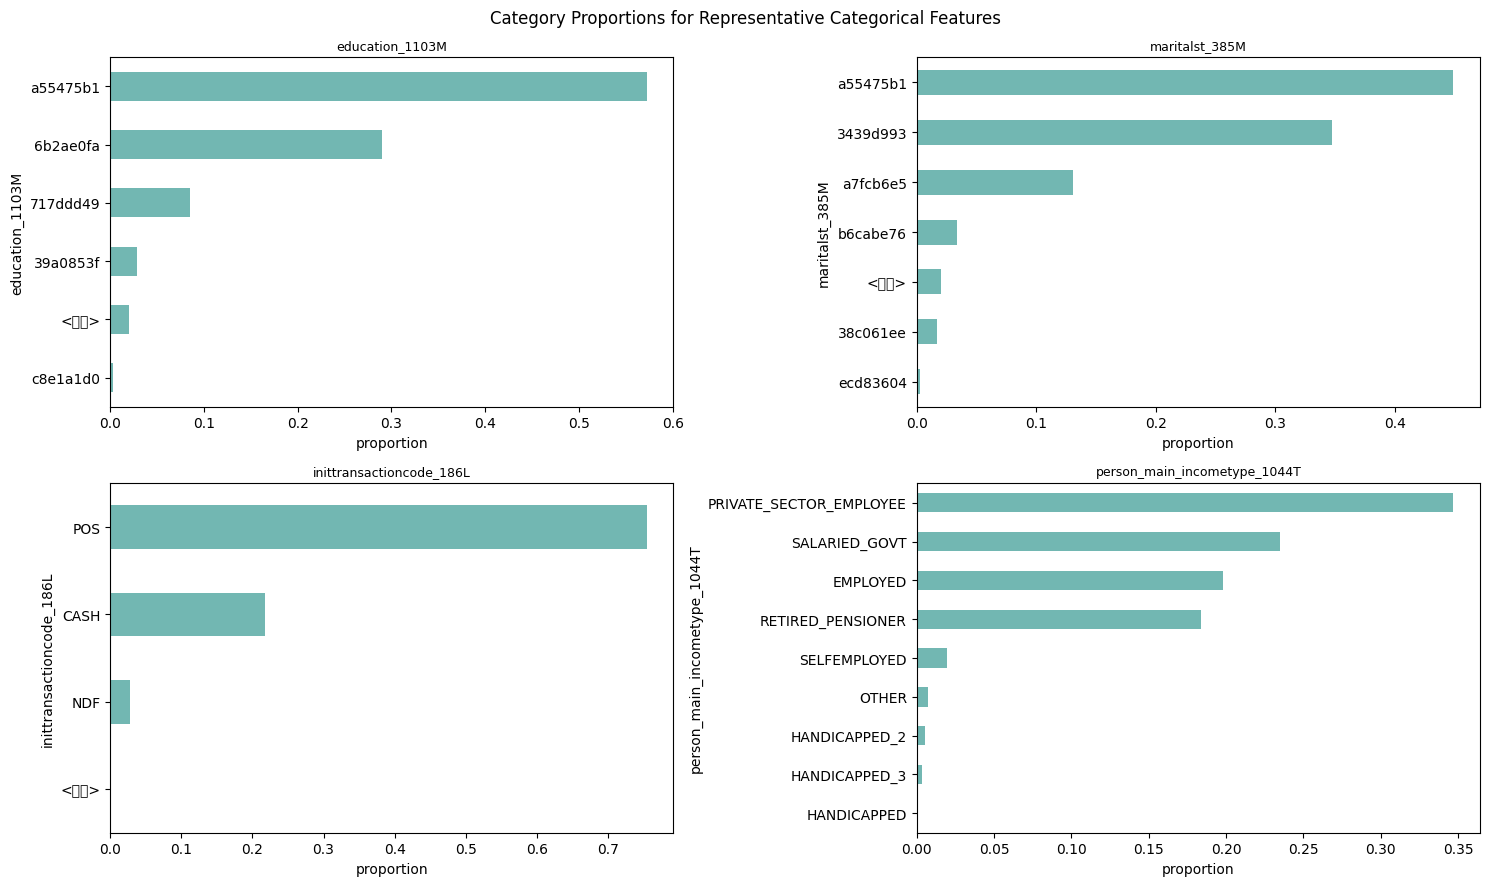

In [4]:
from IPython.display import display, Markdown
categorical_data = (
    eda_sample[categorical_features]
    .astype("string")
)

categorical_summary_rows = []

for feature in categorical_features:
    series = categorical_data[feature]

    value_counts = series.value_counts(
        dropna=True
    )

    if len(value_counts):
        top_value = value_counts.index[0]
        top_count = int(value_counts.iloc[0])
        top_proportion = top_count / len(series)
    else:
        top_value = pd.NA
        top_count = 0
        top_proportion = np.nan

    categorical_summary_rows.append({
        "feature": feature,
        "count": int(series.notna().sum()),
        "missing_rate": float(series.isna().mean()),
        "category_count": int(series.nunique(dropna=True)),
        "top": top_value,
        "top_count": top_count,
        "top_proportion": top_proportion,
    })

categorical_summary = pd.DataFrame(
    categorical_summary_rows
)

display(categorical_summary)

for feature in categorical_features:
    category_table = (
        eda_sample[feature]
        .astype("string")
        .fillna("<缺失>")
        .value_counts(dropna=False)
        .head(10)
        .rename("sample_count")
        .to_frame()
    )

    category_table["proportion"] = (
        category_table["sample_count"]
        / len(eda_sample)
    )

    display(
        Markdown(f"#### `{feature}`")
    )
    display(category_table)

bar_features = categorical_features[:6]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 9),
)

axes = axes.ravel()

for axis, feature in zip(
    axes,
    bar_features,
):
    proportions = (
        eda_sample[feature]
        .astype("string")
        .fillna("<缺失>")
        .value_counts(normalize=True)
        .head(10)
        .sort_values()
    )

    proportions.plot.barh(
        ax=axis,
        color="#72b7b2",
    )

    axis.set_title(feature, fontsize=9)
    axis.set_xlabel("proportion")

for axis in axes[len(bar_features):]:
    axis.axis("off")

fig.suptitle(
    "Category Proportions for Representative Categorical Features"
)
plt.tight_layout()
plt.show()


### 类别特征缺失情况

在本次选取的代表性 categorical features 中，多数字段覆盖较完整。`person_main_familystate_447L` 的缺失率超过 50%，`person_main_gender_992L` 的缺失率约为 99%。对于高缺失字段，不能仅凭类别频数判断其解释价值；还需结合缺失状态与坏账率的关系及后续时间稳定性评估。


## 5. 风险关联：数值特征与 Target

单变量 EDA 只说明变量本身长什么样。接下来检查 numerical feature 和坏账标签之间是否存在基本关系。

这一部分使用两个简单视角：

### 5.1 Pearson correlation

Pearson correlation 描述 numerical feature 和 `target` 之间的线性关系。

- 正值：变量增加时，`target=1` 的倾向整体增加；
- 负值：变量增加时，`target=1` 的倾向整体下降；
- 接近 0：没有明显线性关系。

Pearson 接近 0 不等于变量没有预测价值。U 型、分段或其他非线性关系都可能得到较低 Pearson。

### 5.2 Grouped boxplot

对 Pearson 绝对值相对较高的少量变量，分别查看 `target=0` 和 `target=1` 下的分布。这样可以直接比较两类样本在中位数和整体范围上的差异。

这些结果只作为 EDA 观察，不作为自动删除特征的规则。


,feature,pearson_correlation,abs_correlation
0,pctinstlsallpaidlate1d_3546856L,0.125631,0.125631
1,cbb2_total_payments,-0.027192,0.027192
2,applprev_n_records,0.026930,0.026930
3,credamount_770A,0.026417,0.026417
4,currdebt_22A,0.022986,0.022986
5,price_1097A,0.022776,0.022776
6,numinstls_657L,0.021696,0.021696
7,cba2_total_payments,-0.020922,0.020922
8,annuity_780A,0.016717,0.016717
9,debitcard_record_count,-0.015845,0.015845


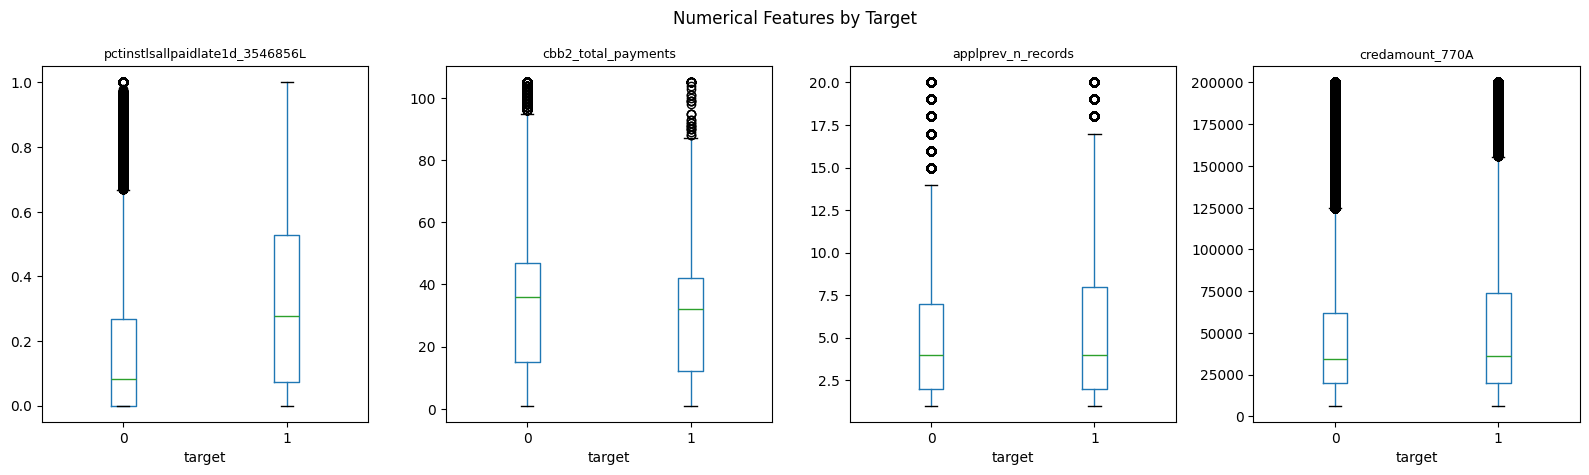

In [5]:
pearson_with_target = (
    numeric_data
    .corrwith(eda_sample[TARGET_COL])
)

numeric_target_relation = (
    pearson_with_target
    .rename("pearson_correlation")
    .to_frame()
)

numeric_target_relation["abs_correlation"] = (
    numeric_target_relation[
        "pearson_correlation"
    ].abs()
)

numeric_target_relation = (
    numeric_target_relation
    .sort_values(
        "abs_correlation",
        ascending=False,
    )
    .rename_axis("feature")
    .reset_index()
)

display(numeric_target_relation)


grouped_boxplot_features = (
    numeric_target_relation
    .head(4)["feature"]
    .tolist()
)

fig, axes = plt.subplots(
    1,
    len(grouped_boxplot_features),
    figsize=(
        4 * len(grouped_boxplot_features),
        4.8,
    ),
)

axes = np.atleast_1d(axes)

for axis, feature in zip(
    axes,
    grouped_boxplot_features,
):
    plot_data = pd.DataFrame({
        TARGET_COL: eda_sample[TARGET_COL],
        feature: numeric_data[feature],
    }).dropna()

    if len(plot_data):
        lower, upper = (
            plot_data[feature]
            .quantile([0.01, 0.99])
        )

        plot_data[feature] = (
            plot_data[feature]
            .clip(lower, upper)
        )

        plot_data.boxplot(
            column=feature,
            by=TARGET_COL,
            ax=axis,
            grid=False,
        )

    axis.set_title(feature, fontsize=9)
    axis.set_xlabel("target")

fig.suptitle(
    "Numerical Features by Target"
)
plt.tight_layout()
plt.show()


## 6. 风险曲线：分箱坏账率

Pearson 只描述线性关系，因此再增加一个更直观的风险视角：把 numerical feature 分成若干区间，再比较各区间的坏账率。

这里使用 `pd.qcut()` 按分位数分成最多 5 箱。理想情况下，每一箱包含接近相同数量的非缺失样本。

每个分箱同时保留：

- `sample_count`
- `bad_count`
- `bad_rate`

这样可以避免只看坏账率而忽略样本量。

分箱图主要用于观察：

- 风险是否随着变量增加而单调上升或下降；
- 是否出现 U 型或其他非线性关系；
- 某些区间是否明显具有更高或更低风险。

这一阶段的分箱只用于 EDA，不用于 WOE、IV 或正式模型预处理。


#### `pctinstlsallpaidlate1d_3546856L`：分箱坏账率

,feature,bin,sample_count,bad_count,bad_rate
0,pctinstlsallpaidlate1d_3546856L,"(-0.001, 0.0364]",352247,6336,0.017987
1,pctinstlsallpaidlate1d_3546856L,"(0.0364, 0.146]",175926,4145,0.023561
2,pctinstlsallpaidlate1d_3546856L,"(0.146, 0.333]",182921,7204,0.039383
3,pctinstlsallpaidlate1d_3546856L,"(0.333, 1.0]",168964,12772,0.075590


#### `cbb2_total_payments`：分箱坏账率

,feature,bin,sample_count,bad_count,bad_rate
0,cbb2_total_payments,"(0.999, 11.0]",5598,441,0.078778
1,cbb2_total_payments,"(11.0, 27.0]",5688,373,0.065577
2,cbb2_total_payments,"(27.0, 37.0]",5770,409,0.070884
3,cbb2_total_payments,"(37.0, 51.0]",4987,284,0.056948
4,cbb2_total_payments,"(51.0, 297.0]",5407,287,0.053079


#### `applprev_n_records`：分箱坏账率

,feature,bin,sample_count,bad_count,bad_rate
0,applprev_n_records,"(0.999, 2.0]",360454,10975,0.030448
1,applprev_n_records,"(2.0, 3.0]",128371,4464,0.034774
2,applprev_n_records,"(3.0, 5.0]",183219,6582,0.035924
3,applprev_n_records,"(5.0, 8.0]",158383,6241,0.039404
4,applprev_n_records,"(8.0, 20.0]",181593,8063,0.044401


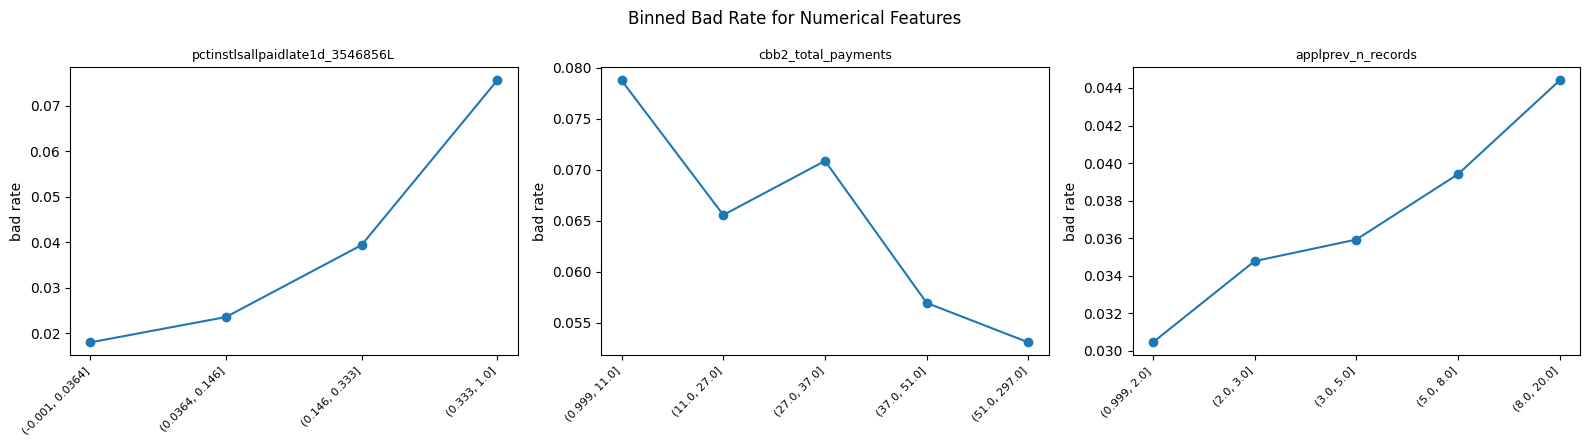

In [6]:
binned_bad_rate_tables = {}

# 对当前选择的numerical features 做分箱坏账率分析
binning_features = (
    numeric_target_relation.head(3)["feature"]
    .tolist()
)

for feature in binning_features:

    values = numeric_data[feature]

    valid_mask = (
        values.notna()
        & eda_sample[TARGET_COL].notna()
    )

    valid_values = values.loc[valid_mask]

    valid_target = eda_sample.loc[
        valid_mask,
        TARGET_COL,
    ]

    # 如果只有一个取值，就没有办法分箱
    if valid_values.nunique() < 2:
        continue

    # 最多分 NUMERIC_BIN_COUNT 箱
    # 如果实际不同取值更少，就减少箱数
    bin_count = min(
        NUMERIC_BIN_COUNT,
        valid_values.nunique(),
    )

    # 按分位数分箱，使每箱样本量尽量接近
    bins = pd.qcut(
        valid_values,
        q=bin_count,
        duplicates="drop",
    )

    # 计算每个箱的样本量、坏账数量和坏账率
    table = (
        pd.DataFrame({
            "bin": bins,
            TARGET_COL: valid_target,
        })
        .groupby(
            "bin",
            observed=True,
        )[TARGET_COL]
        .agg(
            sample_count="size",
            bad_count="sum",
            bad_rate="mean",
        )
        .reset_index()
    )

    table.insert(
        0,
        "feature",
        feature,
    )

    binned_bad_rate_tables[feature] = table

    display(
        Markdown(
            f"#### `{feature}`：分箱坏账率"
        )
    )

    display(table)


# 根据实际特征数量自动创建画布
n_features = len(binned_bad_rate_tables)

n_cols = 3

n_rows = int(
    np.ceil(n_features / n_cols)
)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 4.5 * n_rows),
)

axes = np.array(axes).reshape(-1)


for axis, feature in zip(
    axes,
    binned_bad_rate_tables.keys(),
):

    table = binned_bad_rate_tables[
        feature
    ]

    x = np.arange(len(table))

    axis.plot(
        x,
        table["bad_rate"],
        marker="o",
    )

    axis.set_xticks(x)

    axis.set_xticklabels(
        table["bin"].astype(str),
        rotation=45,
        ha="right",
        fontsize=8,
    )

    axis.set_title(
        feature,
        fontsize=9,
    )

    axis.set_ylabel("bad rate")


# 如果最后一行没有填满，把多余的空图隐藏
for axis in axes[
    len(binned_bad_rate_tables):
]:
    axis.axis("off")


fig.suptitle(
    "Binned Bad Rate for Numerical Features"
)

plt.tight_layout()

plt.show()

### 小结

分箱坏账率显示，部分 numerical features 存在较清晰的风险结构。`pctinstlsallpaidlate1d_3546856L` 和 `applprev_n_records` 的坏账率随特征值增加而明显上升；`credamount_770A` 和 `annuity_780A` 在高值区间出现风险上升，而 `price_1097A`、`maininc_215A` 等变量呈现一定的非线性关系。

部分离散或零值集中的变量由于大量重复取值，`qcut` 实际只能形成 1–2 个分箱，因此暂时不足以判断稳定的风险曲线。当前结果主要用于发现值得进一步验证的特征，不直接作为删除或保留特征的最终依据。

## 7. 类别分层：不同类别的风险差异

对于 categorical feature，最直接的做法是比较不同类别的坏账率。

每个类别同时保留：

- `sample_count`
- `bad_count`
- `bad_rate`

类别坏账率需要和样本量一起解释。如果某个类别只有极少量样本，即使坏账率很高，也不能立即认为它代表稳定的风险模式。

为了保持图表可读性，每个字段只展示样本量最多的前 10 个类别。


#### `education_1103M`：主要类别坏账率

,category,sample_count,bad_count,bad_rate
0,a55475b1,733563,25587,0.034880
1,6b2ae0fa,371568,9972,0.026838
2,717ddd49,109344,3862,0.035320
3,39a0853f,37487,2190,0.058420
4,<缺失>,25877,742,0.028674
5,c8e1a1d0,4243,171,0.040302


#### `maritalst_385M`：主要类别坏账率

,category,sample_count,bad_count,bad_rate
0,a55475b1,575090,19842,0.034502
1,3439d993,444931,13480,0.030297
2,a7fcb6e5,167342,6290,0.037588
3,b6cabe76,42843,1230,0.028709
4,<缺失>,25877,742,0.028674
5,38c061ee,22193,744,0.033524
6,ecd83604,3806,196,0.051498


#### `inittransactioncode_186L`：主要类别坏账率

...

#### `person_main_familystate_447L`：主要类别坏账率

,category,sample_count,bad_count,bad_rate
0,<缺失>,664512,21183,0.031878
1,MARRIED,444887,13674,0.030736
2,SINGLE,118190,5616,0.047517
3,WIDOWED,29578,870,0.029414
4,DIVORCED,17588,761,0.043268
5,LIVING_WITH_PARTNER,7327,420,0.057322


#### `person_main_gender_992L`：主要类别坏账率

,category,sample_count,bad_count,bad_rate
0,<缺失>,1271486,42158,0.033156
1,F,8978,290,0.032301
2,M,1618,76,0.046972


/tmp/ipykernel_58/1941802436.py:95: UserWarning: Glyph 32570 (\N{CJK UNIFIED IDEOGRAPH-7F3A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_58/1941802436.py:95: UserWarning: Glyph 22833 (\N{CJK UNIFIED IDEOGRAPH-5931}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 32570 (\N{CJK UNIFIED IDEOGRAPH-7F3A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 22833 (\N{CJK UNIFIED IDEOGRAPH-5931}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


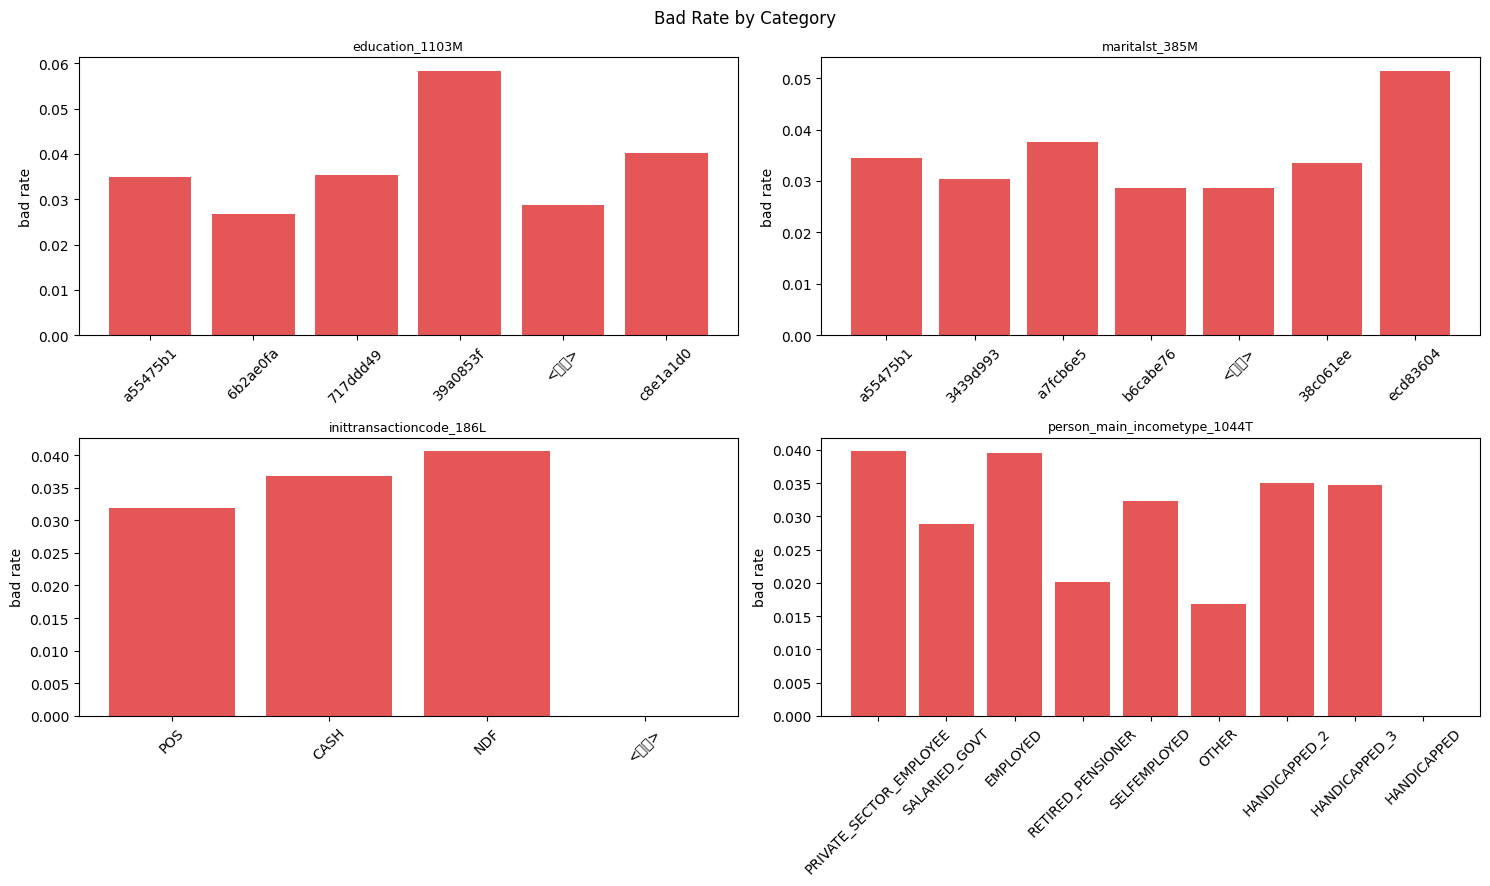

In [7]:
category_bad_rate_tables = {}

for feature in categorical_features:
    values = (
        eda_sample[feature]
        .astype("string")
        .fillna("<缺失>")
    )

    top_categories = (
        values
        .value_counts()
        .head(10)
        .index
    )

    keep_rows = values.isin(
        top_categories
    )

    bad_rate_table = (
        pd.DataFrame({
            "category": values[keep_rows],
            TARGET_COL: eda_sample.loc[
                keep_rows,
                TARGET_COL,
            ],
        })
        .groupby("category")[TARGET_COL]
        .agg(
            sample_count="size",
            bad_count="sum",
            bad_rate="mean",
        )
        .sort_values(
            "sample_count",
            ascending=False,
        )
        .reset_index()
    )

    category_bad_rate_tables[
        feature
    ] = bad_rate_table

    display(
        Markdown(
            f"#### `{feature}`：主要类别坏账率"
        )
    )
    display(bad_rate_table)


plot_category_features = (
    categorical_features[:7]
)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 9),
)

axes = axes.ravel()

for axis, feature in zip(
    axes,
    plot_category_features,
):
    table = category_bad_rate_tables[
        feature
    ]

    axis.bar(
        table["category"].astype(str),
        table["bad_rate"],
        color="#e45756",
    )

    axis.set_title(feature, fontsize=9)
    axis.set_ylabel("bad rate")
    axis.tick_params(
        axis="x",
        rotation=45,
    )

for axis in axes[
    len(plot_category_features):
]:
    axis.axis("off")

fig.suptitle(
    "Bad Rate by Category"
)
plt.tight_layout()
plt.show()


## 8. 缺失信号：Missingness 与风险

缺失值不一定只是数据质量问题。在信用风险数据中，“某个字段为什么没有记录”本身可能和客户历史、数据来源或业务流程有关。

因此对选中的特征比较两组样本：

```text
feature 有值      → observed bad rate
feature 缺失      → missing bad rate
```

并计算：

```text
bad rate gap = missing bad rate - observed bad rate
```

如果差值明显不为 0，说明缺失状态本身可能携带风险信息。

这一结果仍然只是 EDA 证据，不代表后续一定要创建 missing indicator，也不代表缺失具有因果意义。


In [8]:
missing_bad_rate_rows = []

missing_check_features = [
    *numeric_features,
    *categorical_features,
]

for feature in missing_check_features:
    missing_mask = (
        eda_sample[feature].isna()
    )

    missing_count = int(
        missing_mask.sum()
    )

    observed_count = int(
        (~missing_mask).sum()
    )

    missing_bad_rate = (
        eda_sample.loc[
            missing_mask,
            TARGET_COL,
        ].mean()
        if missing_count > 0
        else np.nan
    )

    observed_bad_rate = (
        eda_sample.loc[
            ~missing_mask,
            TARGET_COL,
        ].mean()
        if observed_count > 0
        else np.nan
    )

    missing_bad_rate_rows.append({
        "feature": feature,
        "missing_count": missing_count,
        "missing_rate": (
            missing_count
            / len(eda_sample)
        ),
        "missing_bad_rate": missing_bad_rate,
        "observed_bad_rate": observed_bad_rate,
        "bad_rate_gap": (
            missing_bad_rate
            - observed_bad_rate
            if (
                pd.notna(missing_bad_rate)
                and pd.notna(
                    observed_bad_rate
                )
            )
            else np.nan
        ),
    })

missing_bad_rate_summary = (
    pd.DataFrame(
        missing_bad_rate_rows
    )
)

missing_bad_rate_summary[
    "abs_bad_rate_gap"
] = (
    missing_bad_rate_summary[
        "bad_rate_gap"
    ].abs()
)

missing_bad_rate_summary = (
    missing_bad_rate_summary
    .sort_values(
        "abs_bad_rate_gap",
        ascending=False,
    )
)

display(
    missing_bad_rate_summary.head(20)
)


,feature,missing_count,missing_rate,missing_bad_rate,observed_bad_rate,bad_rate_gap,abs_bad_rate_gap
15,person2_person_count,26910,2.098930e-02,0.067559,0.032431,0.035128,0.035128
7,numinstls_657L,2,1.559963e-06,0.000000,0.033168,-0.033168,0.033168
2,currdebt_22A,2,1.559963e-06,0.000000,0.033168,-0.033168,0.033168
20,inittransactioncode_186L,1,7.799813e-07,0.000000,0.033168,-0.033168,0.033168
14,cbb2_total_payments,1254632,9.785895e-01,0.032464,0.065355,-0.032891,0.032891
13,cbb1_total_records,1254584,9.785521e-01,0.032464,0.065277,-0.032813,0.032813
9,applprev_n_records,270062,2.106433e-01,0.022954,0.035894,-0.012940,0.012940
10,applprev_2_total_records,270062,2.106433e-01,0.022954,0.035894,-0.012940,0.012940
17,deposit_record_count,1196353,9.331330e-01,0.033769,0.024776,0.008994,0.008994
16,debitcard_record_count,1190930,9.289031e-01,0.033802,0.024882,0.008921,0.008921


## 9. 特征结构：相关性与冗余

最后查看选中 numerical features 之间的线性相关关系。

Correlation matrix 中：

- 接近 `+1`：两个变量高度同向变化；
- 接近 `-1`：两个变量高度反向变化；
- 接近 `0`：线性关系较弱。

这一部分的主要作用是发现可能的特征冗余。例如两个聚合特征名称不同，但实际可能在描述非常接近的底层信息。

这里只做记录，不在 EDA 阶段立即删除高相关特征。是否保留需要结合后续模型重要性、稳定性和业务含义再判断。


,credamount_770A,annuity_780A,currdebt_22A,maininc_215A,price_1097A,downpmt_116A,numactivecreds_622L,numinstls_657L,pctinstlsallpaidlate1d_3546856L,applprev_n_records,applprev_2_total_records,cba1_total_records,cba2_total_payments,cbb1_total_records,cbb2_total_payments,person2_person_count,debitcard_record_count,deposit_record_count
credamount_770A,1.000000,0.823329,0.098072,0.118727,0.600890,0.087506,0.062665,0.101283,-0.071253,0.071147,0.079908,0.064004,0.109474,0.070853,0.068442,-0.007168,0.016419,0.015644
annuity_780A,0.823329,1.000000,0.052503,0.117550,0.537101,0.098070,0.030924,0.040881,-0.057227,0.046865,0.059040,0.048768,0.089145,0.039012,0.053179,-0.027249,0.015360,0.014937
currdebt_22A,0.098072,0.052503,1.000000,0.228350,0.001013,-0.010462,0.540093,0.729022,-0.083300,0.273799,0.267298,0.105663,0.138500,0.206972,0.078628,-0.068876,0.034778,0.026659
maininc_215A,0.118727,0.117550,0.228350,1.000000,0.115466,0.021384,0.194350,0.174096,-0.116795,0.140813,0.128927,0.126402,0.125822,0.187793,0.127433,-0.011558,0.014389,0.009741
price_1097A,0.600890,0.537101,0.001013,0.115466,1.000000,0.291660,-0.060814,-0.059212,-0.004025,-0.065628,-0.057113,0.013094,0.038199,0.024319,0.043880,0.043567,0.007311,0.011290
downpmt_116A,0.087506,0.098070,-0.010462,0.021384,0.291660,1.000000,-0.024044,-0.022523,0.002746,-0.024236,-0.024019,-0.005428,-0.005473,-0.004612,0.003246,0.015265,0.001500,0.003108
numactivecreds_622L,0.062665,0.030924,0.540093,0.194350,-0.060814,-0.024044,1.000000,0.714509,-0.134020,0.336772,0.299967,0.113661,0.137857,0.352047,0.117073,-0.117485,0.107651,0.077634
numinstls_657L,0.101283,0.040881,0.729022,0.174096,-0.059212,-0.022523,0.714509,1.000000,-0.077577,0.312970,0.292121,0.097013,0.130506,0.266505,0.131626,-0.091997,0.029881,0.021026
pctinstlsallpaidlate1d_3546856L,-0.071253,-0.057227,-0.083300,-0.116795,-0.004025,0.002746,-0.134020,-0.077577,1.000000,0.060318,0.052116,0.012473,0.040196,-0.006550,0.007130,0.004949,-0.086495,-0.084264
applprev_n_records,0.071147,0.046865,0.273799,0.140813,-0.065628,-0.024236,0.336772,0.312970,0.060318,1.000000,0.939379,0.357706,0.409768,0.263830,0.128834,-0.082467,0.103966,0.083903


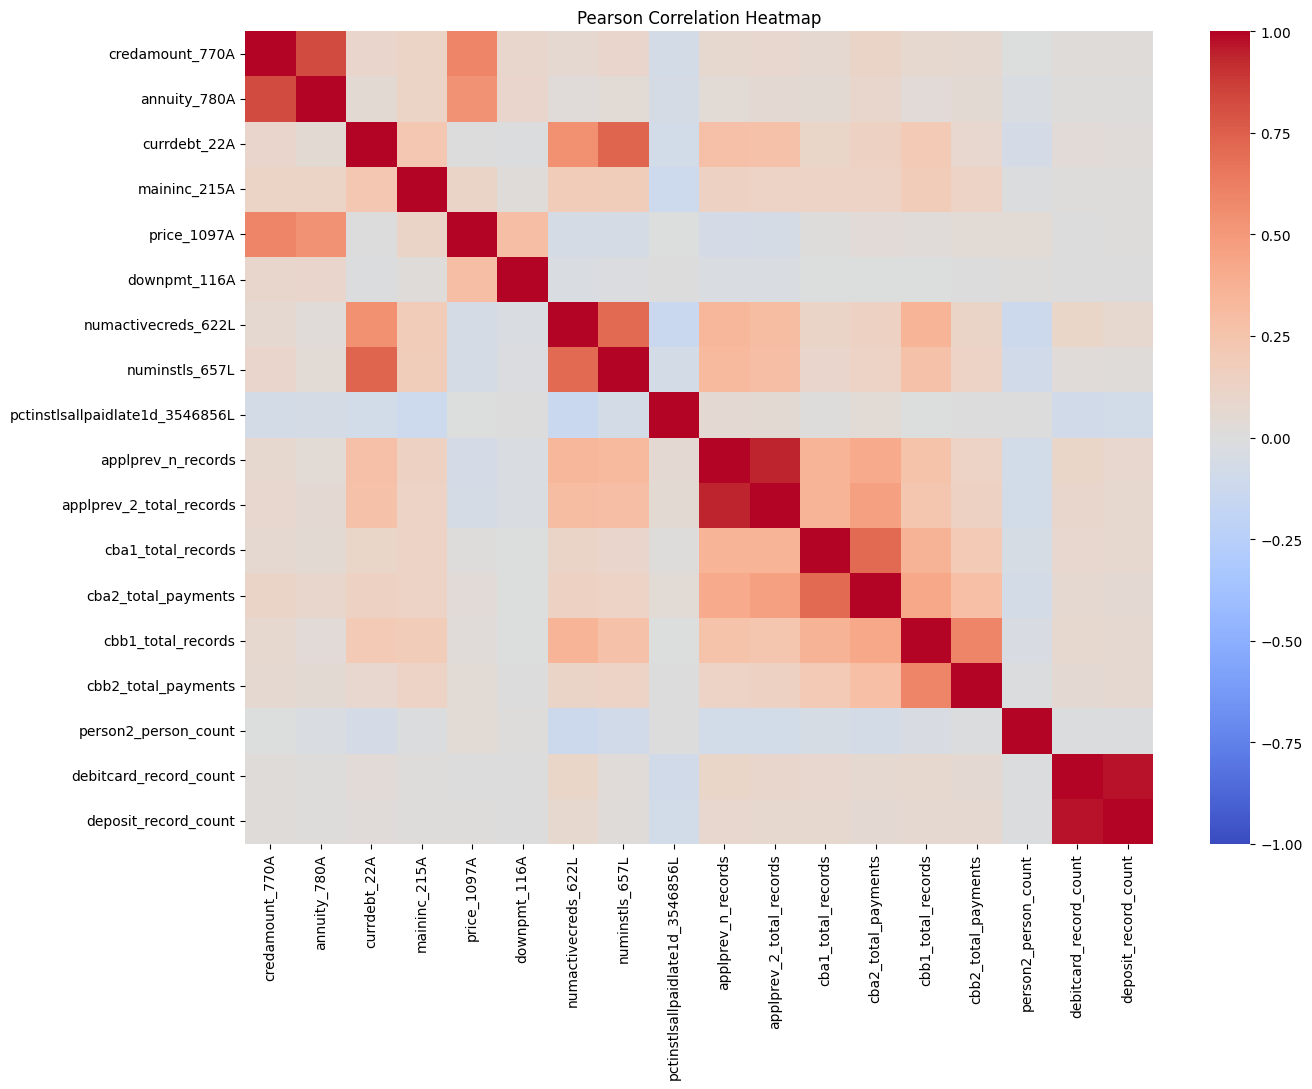

In [9]:
correlation_matrix = numeric_data.corr(
    method="pearson"
)

display(correlation_matrix)

plt.figure(figsize=(14, 11))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)

plt.title(
    "Pearson Correlation Heatmap"
)

plt.tight_layout()
plt.show()


## 10. 结果沉淀：EDA 输出

本轮 EDA 主要生成以下结果：

- target 分布；
- 每周坏账率；
- numerical feature 单变量统计；
- categorical feature 单变量统计；
- numerical feature 与 target 的 Pearson correlation；
- numerical feature 分箱坏账率；
- categorical feature 类别坏账率；
- missing / non-missing 坏账率；
- numerical feature correlation matrix。

这些文件保存到：

```text
/kaggle/working/reports/feature_eda
```

本 Notebook 不生成新的训练数据，也不修改 Notebook 5 已经清洗好的数据。


In [10]:
TARGET_TABLE_PATH = (
    REPORT_ROOT / "target_distribution.csv"
)
WEEKLY_TARGET_PATH = (
    REPORT_ROOT / "weekly_target.csv"
)
NUMERIC_SUMMARY_PATH = (
    REPORT_ROOT / "numeric_summary.csv"
)
CATEGORICAL_SUMMARY_PATH = (
    REPORT_ROOT / "categorical_summary.csv"
)
NUMERIC_TARGET_PATH = (
    REPORT_ROOT / "numeric_target_relation.csv"
)
NUMERIC_BIN_PATH = (
    REPORT_ROOT / "numeric_binned_bad_rate.csv"
)
CATEGORY_BAD_RATE_PATH = (
    REPORT_ROOT / "categorical_bad_rate.csv"
)
MISSING_BAD_RATE_PATH = (
    REPORT_ROOT / "missing_bad_rate.csv"
)
CORRELATION_MATRIX_PATH = (
    REPORT_ROOT / "correlation_matrix.csv"
)

target_table.to_csv(
    TARGET_TABLE_PATH
)

weekly_target.to_csv(
    WEEKLY_TARGET_PATH,
    index=False,
)

numeric_summary.to_csv(
    NUMERIC_SUMMARY_PATH,
    index=False,
)

categorical_summary.to_csv(
    CATEGORICAL_SUMMARY_PATH,
    index=False,
)

numeric_target_relation.to_csv(
    NUMERIC_TARGET_PATH,
    index=False,
)

if binned_bad_rate_tables:
    numeric_binned_bad_rate = pd.concat(
        binned_bad_rate_tables.values(),
        ignore_index=True,
    )
else:
    numeric_binned_bad_rate = pd.DataFrame()

numeric_binned_bad_rate.to_csv(
    NUMERIC_BIN_PATH,
    index=False,
)

category_bad_rate_parts = []

for feature, table in (
    category_bad_rate_tables.items()
):
    part = table.copy()
    part.insert(
        0,
        "feature",
        feature,
    )
    category_bad_rate_parts.append(
        part
    )

if category_bad_rate_parts:
    categorical_bad_rate = pd.concat(
        category_bad_rate_parts,
        ignore_index=True,
    )
else:
    categorical_bad_rate = pd.DataFrame()

categorical_bad_rate.to_csv(
    CATEGORY_BAD_RATE_PATH,
    index=False,
)

missing_bad_rate_summary.to_csv(
    MISSING_BAD_RATE_PATH,
    index=False,
)

correlation_matrix.to_csv(
    CORRELATION_MATRIX_PATH
)

print("EDA 结果目录：", REPORT_ROOT)


EDA 结果目录： /kaggle/working/reports/feature_eda


## 11. Key Findings：从代表性 EDA 到后续建模

本轮 EDA 只选取了约 20 个具有代表性的 numerical / categorical features 进行深入观察，而原始宽表中仍有 1000 多个候选特征。

因此，这一阶段的结论应理解为：

> **通过一组代表性特征了解当前数据可能存在的结构和风险模式，并据此设计后续建模与 Feature Selection。**

本轮 EDA 并不能证明全部 1000 多个特征都具有相同的分布或预测关系，也不会直接决定最终应该保留或删除哪些字段。后续 Feature Selection 仍需要对完整候选特征池进行系统计算和验证。

---

### 11.1 Target 与时间结构：风险环境需要按时间验证

对 `target` 的整体和时间分布观察表明，坏账率并不是在整个时间范围内完全稳定。

尤其是在后期可以观察到较明显的风险水平变化，这说明模型面对的并不是一个完全静态的数据环境。

这一发现与具体选择了哪些代表性特征无关，因为它直接来自 `target` 本身。因此后续建模继续采用：

```text
Train → Validation → OOT
```

的时间顺序，而不是随机 Train/Test Split。

同时，后续评价不能只关注 AUC、Gini 和 KS 等排序指标。

如果未来时期的总体坏账率发生变化，即使客户排序仍然比较稳定，预测出来的违约概率也可能与实际坏账率发生偏离，因此还需要继续关注：

```text
Mean Predicted PD
Observed Bad Rate
O/E
Calibration
```

OOT 继续保持封存，只在特征池、模型和参数全部确定之后用于最终检验。

---

### 11.2 代表性特征显示出复杂的数据结构

在本轮选取的代表性 numerical features 中，可以观察到多种不同的数据结构：

- 金额、收入和负债类变量中存在明显右偏和长尾；
- 部分变量包含较多极端值；
- 部分变量存在大量真实 `0`；
- 一些 numerical features 实际上属于离散计数变量；
- 不同字段的 Missingness 差异较大。

这些现象说明，至少在当前观察到的特征中，不能简单采用：

```text
Outlier → 删除
High Missing Rate → 删除
Zero → 异常值
```

这样的机械规则。

Boxplot 中的 outlier 可能是真实的高金额、高负债或特殊客户，而大量 `0` 也可能代表真实业务状态。

同样，高缺失字段也不一定没有价值。Missingness 可能与数据来源、客户类型或业务流程有关，因此后续需要进一步检查：

```text
Missing
vs
Observed
```

是否具有稳定的风险差异。

需要注意的是，这些结论目前只来自代表性特征。后续面对完整特征池时，还需要重新计算每个字段的 Missingness、基数、分布和数据质量指标。

---

### 11.3 代表性风险关系表明：单一指标不足以完成 Feature Selection

在本轮选取的 numerical features 中，多数变量与 `target` 的 Pearson correlation 较弱。

其中 `pctinstlsallpaidlate1d_3546856L` 的线性关系相对更加明显，而其他代表性变量大多只有较弱的 marginal linear relationship。

但是，这个结果只能说明：

> **当前被选出来观察的这些代表性变量中，单变量线性关系整体偏弱。**

它不能推出：

> **全部 1000 多个特征的 Pearson 都很弱。**

因此，Pearson 仍然可以在后续 Feature Selection 中对完整 numerical feature pool 进行批量计算，并作为衡量线性单变量信号的一项指标。

本轮 EDA 真正提供的启发是：

```text
Pearson low
≠
Feature useless
```

因为进一步查看分箱坏账率后，一些代表性特征虽然 Pearson 并不高，但仍然表现出有组织的风险结构。

例如：

- `pctinstlsallpaidlate1d_3546856L` 的坏账率随变量增加明显上升；
- `applprev_n_records` 也表现出较清晰的风险上升趋势；
- `credamount_770A`、`annuity_780A` 在高值区间出现风险抬升；
- `price_1097A`、`maininc_215A` 等变量出现一定的非线性或阈值结构。

这说明至少在当前代表性特征中，线性关系并不能完整描述变量与风险之间的关系。

因此后续 Feature Selection 可以继续使用 Pearson，但不能只使用 Pearson。

更合理的是同时观察：

```text
Pearson
+
IV
+
|Univariate AUC - 0.5|
+
LGBM-ref Importance
```

其中：

- Pearson 反映线性关系；
- IV 反映分箱后好坏客户的区分程度；
- Univariate AUC 反映单变量排序能力；
- LightGBM importance 可以提供非线性和交互环境下的模型侧证据。

同样，本轮 Correlation Matrix 只覆盖代表性 numerical features，因此只能说明当前观察到的部分字段之间存在潜在冗余。

后续真正的冗余筛选仍然需要在更完整的候选池上重新计算，而不能直接根据 Notebook 6 的小型 Correlation Matrix 删除特征。

---

### 11.4 EDA 的真正贡献：确定后续应该检查什么，而不是提前决定答案

因此，本轮 EDA 最重要的作用不是总结“1000 多个特征整体都怎么样”，而是通过代表性变量提前发现几类值得在完整特征池中系统验证的问题。

#### 1. 时间问题

```text
Target 随时间存在明显变化
        ↓
后续必须进行时间外验证
        ↓
同时检查 Ranking 与 Calibration
```

#### 2. 数据质量与 preprocessing 问题

```text
代表性特征存在
Long Tail / Missing / Zero / Outlier
        ↓
不能使用简单机械删除规则
        ↓
需要固定且一致的 preprocessing
```

因此 Logistic Regression 后续需要统一处理：

```text
Numerical
→ Missing handling
→ Missing indicator
→ Standardisation

Categorical
→ Missing handling
→ Rare category handling
→ One-Hot Encoding
```

#### 3. 单变量信号问题

```text
部分代表性特征 Pearson 较弱
但仍可能存在非线性风险结构
        ↓
Pearson 可以继续使用
但不能作为唯一筛选标准
```

后续将在完整特征池上系统计算多个指标，而不是根据 Notebook 6 中观察的二十多个变量直接推广到全部字段。

#### 4. 非线性问题

```text
部分代表性特征存在
Threshold / Monotonic / U-shaped relationship
        ↓
线性模型可能无法完整利用这些信息
        ↓
需要 LGBM-ref 作为非线性参考
```

因此下一阶段同时建立：

```text
Full-feature Logistic Regression Baseline
+
LGBM-ref
```

Logistic Regression 提供线性基准，LGBM-ref 则用于检查完整候选特征池中的非线性和交互信息，并为后续 Feature Selection 提供模型侧重要性。

#### 5. Feature Selection 问题

Notebook 6 只是提出筛选假设，真正的 Feature Selection 将在完整候选特征池上完成。

后续不会直接使用 EDA 中观察到的二十多个变量作为最终模型特征，而是从完整 raw candidate pool 出发：

```text
Raw Candidate Features
        ↓
完整数据质量检查
        ↓
单变量预测信号
Pearson / IV / |AUC - 0.5|
        ↓
Feature Redundancy
        ↓
Temporal Stability
        ↓
LGBM-ref Importance
        ↓
最终构建
features_full
features_stable
features_predictive_matched
```

其中 Pearson、IV、单变量 AUC、PSI 或 LightGBM importance 都不会被单独视为绝对的删除标准。

例如：

```text
Low Pearson
```

只能说明线性单变量关系较弱；

```text
High PSI
```

只能说明特征分布发生变化；

```text
Low Univariate AUC
```

只能说明变量单独排序能力有限。

最终筛选需要结合多项证据，而不是让一个指标直接决定变量命运。

---

### 11.5 从 EDA 进入 Baseline Modeling

综上，本轮 EDA 的价值可以概括为：

```text
不是：
20 多个代表性特征
→ 推断全部 1000 多个特征都一样

而是：
20 多个代表性特征
→ 发现可能存在的数据问题和风险结构
→ 形成后续需要验证的假设
→ 在完整候选特征池上系统检验
```

因此下一阶段首先建立未经预测型 Feature Selection 的：

```text
Raw Candidate Features
        ↓
Full-feature Logistic Regression Baseline
        +
LGBM-ref
```

先得到完整候选特征池下的原始模型表现和模型侧的重要性信息。

随后再进入正式 Feature Selection，在完整特征池上验证 Notebook 6 中观察到的：

- 单变量预测力；
- 非线性风险关系；
- Missingness；
- 特征冗余；
- 时间稳定性；

是否真正具有普遍且稳定的建模价值。

因此，Notebook 6 的角色不是替代 Feature Selection，而是为后续 Feature Selection 和 Baseline Modeling 提供数据层面的方向与假设。